# PaperLab end to end

Run the custom BPE and NumPy Mini-GPT learning lab, then retrieve evidence from PDFs. This notebook uses the source files in **PaperLab_Complete_Project.zip**. Keep it inside the extracted project's notebooks folder, or upload the ZIP when prompted in Colab.

The tiny model learns next-token prediction. It is **not** the PDF question-answering engine. Offline evidence works without model downloads; FLAN-T5 is optional. Full mathematical and component explanations are in `docs/PROJECT_GUIDE.md`.


In [1]:
from pathlib import Path
import sys, importlib.util, subprocess, json
root = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd()/"PaperLab"]
             if (p/"paperlab/tokenizer.py").exists()), None)
if root is None:
    try:
        from google.colab import files
    except ImportError:
        raise RuntimeError("Extract PaperLab_Complete_Project.zip and open this notebook inside its notebooks folder.")
    import zipfile, io
    print("Upload PaperLab_Complete_Project.zip")
    uploaded = files.upload()
    name = next((n for n in uploaded if n.endswith(".zip")), None)
    if name is None:
        raise ValueError("Upload the project ZIP.")
    dest = Path.cwd().resolve()
    with zipfile.ZipFile(io.BytesIO(uploaded[name])) as z:
        for member in z.infolist():
            if not (dest/member.filename).resolve().is_relative_to(dest):
                raise ValueError("Unsafe archive path")
        z.extractall(dest)
    root = dest/"PaperLab"
if not (root/"paperlab/tokenizer.py").exists():
    raise RuntimeError("The ZIP did not contain the expected PaperLab project.")
sys.path.insert(0, str(root))
if any(importlib.util.find_spec(m) is None for m in ["numpy", "pypdf", "threadpoolctl", "fastapi", "uvicorn"]):
    subprocess.check_call([sys.executable,"-m","pip","install","-r",str(root/"requirements.txt")])
DATA = root/"data/starter"
RUN = root/"runs/notebook"
RUN.mkdir(parents=True, exist_ok=True)
print("Project ready. Starter files:", [p.name for p in (DATA/"papers").glob("*.pdf")])


Project ready. Starter files: ['retrieval_ranks.pdf', 'window_overlap.pdf', 'sensor_filter.pdf']


## 1 Inspect data and split boundaries

There are 30 training notes and 6 validation notes. Duplicate IDs or normalized texts are rejected. The tokenizer will train on the training partition only. These notes and the QA questions are educational fixtures, not an unseen research benchmark.


In [2]:
from paperlab.training import load_corpus
groups = load_corpus(DATA/"corpus.jsonl")
print({split:len(docs) for split,docs in groups.items()})
print(groups["train"][0])


{'train': 30, 'validation': 6}
Research questions. A research question tells the reader what the experiment is designed to discover. A useful question names the population, the input, the decision and the evidence needed to support an answer. For a paper search tool we might ask how often the first three passages include the sentence a reader needs. The answer depends on both the questions and the collection of papers.


## 2 Learn byte-level BPE

IDs 0–255 represent UTF-8 bytes. PAD, BOS and EOS are 256, 257 and 258. Frequent adjacent pairs become new IDs. The target vocabulary 448 allows up to 189 learned merges. This tokenizer belongs to the custom model, not FLAN-T5.


In [3]:
from paperlab.tokenizer import ByteBPE
tokenizer = ByteBPE.train(groups["train"], vocab_size=448)
for text in ["Research questions", "नमस्ते भारत 🙂", "a\n  b"]:
    ids = tokenizer.encode(text)
    assert tokenizer.decode(ids) == text
    print(repr(text), "bytes:", len(text.encode()), "tokens:", len(ids), "IDs:", ids)
print("Vocabulary:", tokenizer.vocab_size, "First merges:", tokenizer.merges[:8])


'Research questions' bytes: 18 tokens: 6 IDs: [82, 272, 101, 279, 331, 444]
'नमस्ते भारत 🙂' bytes: 36 tokens: 36 IDs: [224, 164, 168, 224, 164, 174, 224, 164, 184, 224, 165, 141, 224, 164, 164, 224, 165, 135, 32, 224, 164, 173, 224, 164, 190, 224, 164, 176, 224, 164, 164, 32, 240, 159, 153, 130]
'a\n  b' bytes: 5 tokens: 5 IDs: [97, 10, 32, 32, 98]
Vocabulary: 448 First merges: ((32, 116), (104, 101), (32, 97), (105, 110), (101, 110), (111, 110), (259, 260), (114, 101))


## 3 Inspect the causal Transformer

The model has two blocks, width 48 and four attention heads. It uses learned token/position embeddings, causal attention, GELU, layer normalization and tied output embeddings. Future positions are masked before attention softmax.


In [4]:
import numpy as np
from paperlab.model import MiniGPT, Config
model = MiniGPT(Config(vocab=tokenizer.vocab_size))
sample = np.array([tokenizer.encode("Research questions")])
logits = model.forward(sample)
print("Input:", sample.shape, "Logits:", logits.shape)
print("Parameters:", model.parameter_count)
assert model.parameter_count == 79584


Input: (1, 6) Logits: (1, 6, 448)
Parameters: 79584


## 4 Train and select the best validation checkpoint

The next-token loss ignores padded targets. Backpropagation is written in NumPy, including the attention derivatives. AdamW uses clipped gradients. The run below performs 400 optimizer updates and saves the best measured validation state. It writes a separate notebook checkpoint so the supplied reference run remains available.


In [5]:
import time
from paperlab.training import train
started = time.perf_counter()
model, tokenizer, training = train(DATA/"corpus.jsonl", RUN/"mini_gpt.npz", steps=400)
training["wall_seconds"] = time.perf_counter()-started
(RUN/"training.json").write_text(json.dumps(training,indent=2))
print("Best step:",training["best_step"], "Perplexity:",round(training["validation_perplexity"],2))
print("Elapsed seconds:",round(training["wall_seconds"],2))


step    0 | train 6.112 | validation 6.117
step   50 | train 4.844 | validation 4.875
step  100 | train 4.042 | validation 4.238
step  150 | train 3.616 | validation 3.998
step  200 | train 3.312 | validation 3.845
step  250 | train 3.102 | validation 3.839
step  300 | train 2.879 | validation 3.930
step  350 | train 2.719 | validation 4.013
step  400 | train 2.521 | validation 4.179
Best step: 250 Perplexity: 46.49
Elapsed seconds: 9.82


## 5 Read the learning curve

If training loss falls while validation loss rises, the model is overfitting. Loss is in nats per BPE token; perplexity is its exponential. Neither number is document-answer accuracy. The validation set selects a checkpoint and is not a final untouched test set.


   0: train=6.112, validation=6.117
  50: train=4.844, validation=4.875
 100: train=4.042, validation=4.238
 150: train=3.616, validation=3.998
 200: train=3.312, validation=3.845
 250: train=3.102, validation=3.839
 300: train=2.879, validation=3.930
 350: train=2.719, validation=4.013
 400: train=2.521, validation=4.179


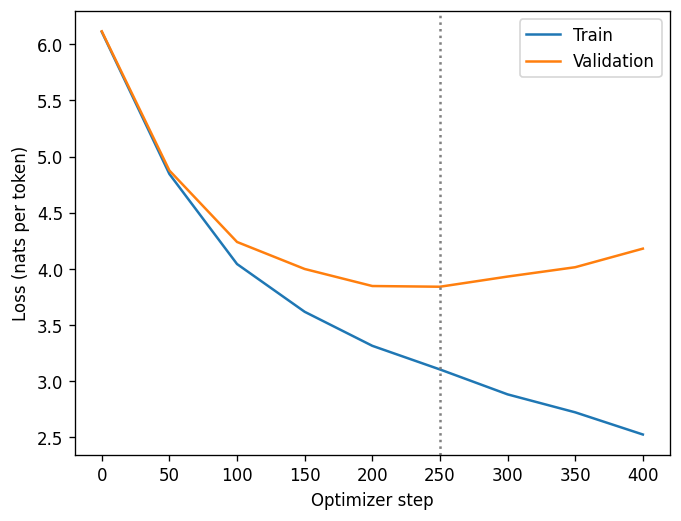

In [6]:
for row in training["history"]:
    print(f"{row['step']:>4}: train={row['train_loss']:.3f}, validation={row['validation_loss']:.3f}")
if importlib.util.find_spec("matplotlib"):
    import matplotlib.pyplot as plt
    plt.plot([h["step"] for h in training["history"]],[h["train_loss"] for h in training["history"]],label="Train")
    plt.plot([h["step"] for h in training["history"]],[h["validation_loss"] for h in training["history"]],label="Validation")
    plt.axvline(training["best_step"],linestyle=":",color="gray")
    plt.xlabel("Optimizer step");plt.ylabel("Loss (nats per token)");plt.legend();plt.show()


## 6 Load and sample

The checkpoint contains its matching tokenizer. Sampling uses a 48-token context, temperature 0.7 and top-k 20. The small model produces imperfect continuations. It has no key/value cache and must not be treated as a factual QA engine.


In [7]:
from paperlab.training import load_checkpoint, generate
restored, saved_tokenizer, saved_report = load_checkpoint(RUN/"mini_gpt.npz")
print(generate(restored,saved_tokenizer,"Research questions",max_new_tokens=64))


Research questions whening a position. hening the model model a readervidentiflefficurrank rongeding a model a position and the howow of a readermity. An a sy 


## 7 Extract PDFs and preserve page identity

Chunks contain at most 130 whitespace words with 28-word overlap. They never cross pages. These six short pages happen to fit into six chunks. Scanned PDFs need external OCR.


In [8]:
from paperlab.retrieval import read_papers
from paperlab.ranking import RetrievalIndex
passages, issues = read_papers(DATA/"papers")
index = RetrievalIndex(passages,mode="bm25")
print("Passages:",len(passages),"Issues:",issues)
for hit in index.search("What was the alarm threshold in the distance experiment?",3):
    print(hit.passage.citation,"score:",round(hit.score,3),"coverage:",round(hit.coverage,3))
    print(hit.passage.text)


Passages: 6 Issues: []
sensor_filter.pdf, p. 1 score: 6.364 coverage: 1.0
PAPERLAB / TEACHING COLLECTION Detecting a distance spike The alarm threshold was 80 centimetres. A raw distance reading triggered an alarm only when it exceeded this threshold. We constructed a short trace with one isolated spike to inspect the behavior of a filtering rule. Raw distance readings 41 42 116 43 44 (centimetres) Rule for a raw alarm distance > threshold Filter design We used a centred median filter with a window of three readings. A filtered value was calculated only where a sample had a neighbor on both sides. This choice leaves the first and last positions without a filtered value. Distance filtering experiment 1 / 2
sensor_filter.pdf, p. 2 score: 3.088 coverage: 0.581
PAPERLAB / TEACHING COLLECTION The median at the spike The filtered distance at the spike was 43 centimetres. Its neighborhood contained 42, 116 and 43 centimetres. Sorting those three values placed 43 in the middle, replacing the i

## 8 Ask with offline evidence

Offline mode selects an evidence sentence. It does not call a generative model. The returned wording must occur in the retrieved source. That check verifies wording, not the semantics of the answer.


In [9]:
from paperlab.rag import answer
from paperlab.generators import ExtractiveGenerator
offline = ExtractiveGenerator()
for question in ["What was the alarm threshold in the distance experiment?", "Who manufactured the distance sensor?"]:
    reply=answer(index,offline,question)
    print("QUESTION:",question,"STATUS:",reply.status)
    print(reply.display(),"\n")


QUESTION: What was the alarm threshold in the distance experiment? STATUS: answered
PAPERLAB / TEACHING COLLECTION Detecting a distance spike The alarm threshold was 80 centimetres [sensor_filter.pdf, p. 1]
Evidence: “PAPERLAB / TEACHING COLLECTION Detecting a distance spike The alarm threshold was 80 centimetres.” 

QUESTION: Who manufactured the distance sensor? STATUS: no_supported_span
I could not verify an answer in the retrieved passages. 



## 9 Optional pretrained RAG

Set ENABLE_FLAN=True to install optional dependencies and download FLAN-T5-small on the first run. It uses its own tokenizer and a 512-token input budget. This adapter was tested with the real model in the build benchmark. The default notebook skips this download.


In [10]:
ENABLE_FLAN = False
generator = offline
if ENABLE_FLAN:
    subprocess.check_call([sys.executable,"-m","pip","install","-r",str(root/"requirements-llm.txt")])
    from paperlab.generators import make_generator
    generator=make_generator("flan")
    print(answer(index,generator,"What was the alarm threshold in the distance experiment?").display())
else:
    print("FLAN skipped. Offline evidence remains active.")


FLAN skipped. Offline evidence remains active.


## 10 Evaluate retrieval, answers and abstention

Page Hit@3 and MRR@3 use distinct physical pages. Short-answer exact match is strict and penalizes full-sentence evidence output. Reference containment is a permissive diagnostic, not a semantic correctness guarantee. The 13 fixtures were visible during development.


In [11]:
from paperlab.evaluation import evaluate
for mode in ["bm25","tfidf","hybrid"]:
    report=evaluate(RetrievalIndex(passages,mode=mode),DATA/"qa.json")
    print(mode,report["metrics"])
evaluation=evaluate(index,DATA/"qa.json",generator=generator)
(RUN/"evaluation.json").write_text(json.dumps(evaluation,indent=2))
print("Answer metrics:",json.dumps(evaluation["metrics"],indent=2))
for case in evaluation["cases"]:
    print(case["status"],case["question"],"=>",case["answer"])


bm25 {'k': 3, 'answerable': 10, 'unanswerable': 3, 'page_hit@3': 1.0, 'page_mrr@3': 0.95}
tfidf {'k': 3, 'answerable': 10, 'unanswerable': 3, 'page_hit@3': 1.0, 'page_mrr@3': 0.95}
hybrid {'k': 3, 'answerable': 10, 'unanswerable': 3, 'page_hit@3': 1.0, 'page_mrr@3': 0.95}
Answer metrics: {
  "k": 3,
  "answerable": 10,
  "unanswerable": 3,
  "page_hit@3": 1.0,
  "page_mrr@3": 0.95,
  "answer_exact_match": 0.0,
  "answer_and_page_correct": 0.0,
  "reference_containment_and_page": 0.7,
  "accepted_answer_rate": 0.9,
  "unanswerable_abstention_rate": 1.0
}
answered What was the alarm threshold in the distance experiment? => PAPERLAB / TEACHING COLLECTION Detecting a distance spike The alarm threshold was 80 centimetres
no_supported_span Which statistic was the distance filter based on? => I could not verify an answer in the retrieved passages.
answered What was the filtered distance at the spike? => PAPERLAB / TEACHING COLLECTION Detecting a distance spike The alarm threshold was 80 centi

## 11 Inspect the saved real FLAN benchmark

The following is the reference build measurement rather than a new FLAN invocation. The real model achieved 7/10 exact answers and 3/3 unanswerable abstentions on this development set. Read the failed cases: literal citations can still support the wrong answer.


In [12]:
reference=json.loads((root/"runs/benchmark.json").read_text())
if "flan" in reference["answers"]:
    print(reference["answers"]["flan"]["metrics"])
    for case in reference["answers"]["flan"]["cases"]:
        if case["answerable"] and not case["exact_match"]:
            print("FAILED:",case["question"],"=>",case["answer"],"SOURCE:",case["citation"])


{'k': 3, 'answerable': 10, 'unanswerable': 3, 'page_hit@3': 1.0, 'page_mrr@3': 0.95, 'answer_exact_match': 0.7, 'answer_and_page_correct': 0.7, 'reference_containment_and_page': 0.7, 'accepted_answer_rate': 1.0, 'unanswerable_abstention_rate': 1.0}
FAILED: Which statistic was the distance filter based on? => A filtered value was calculated only where a sample had a neighbor on both sides. This choice leaves the first and last positions without a filtered value. Distance filtering experiment 1 / 2 SOURCE: sensor_filter.pdf, p. 1
FAILED: What was the filtered distance at the spike? => 80 centimetres SOURCE: sensor_filter.pdf, p. 1
FAILED: How many filtered alarms remained on comparable interior positions? => 1 SOURCE: sensor_filter.pdf, p. 2


## 12 Export this run

The source project already includes its reference run. The ZIP below contains only this notebook's newly produced checkpoint and reports. In Colab, uncomment the download line. To run the dashboard, extract the main project on your computer and follow the README.


In [13]:
import zipfile
export = RUN/"notebook_run.zip"
with zipfile.ZipFile(export,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for name in ["mini_gpt.npz","training.json","evaluation.json"]:
        z.write(RUN/name,arcname=name)
print("Notebook run exported to",export.name)
# In Colab: files.download(str(export))


Notebook run exported to notebook_run.zip


## Complexity and further work

Sparse retrieval costs O(F + r log r), where F is the sum of matching posting lengths and r is the candidate count, plus query normalization. One Transformer batch costs O(L B (T d² + T² d) + B T d V). Training repeats forward/backward updates and adds optimizer and evaluation costs.

Read the full project guide for the derivation, space complexity, technology choices, failure analysis, code map and viva answers. Next experiments should use held-out real questions, investigate semantic citation verification and compare reranking or chunking under a fixed evaluation protocol.
